# EDA — additional application-time feature candidates

This notebook evaluates the requested candidates without changing the bronze, silver, or gold tables:

1. `total_credit_products`
2. `inquiries_per_credit_year`
3. `delays_per_credit_year`
4. `debt_x_interest`
5. Multi-hot loan-type indicators
6. A small clickstream recency/volatility subset

It also checks whether one-hot encoded **loan type** and **occupation** add validation value beyond the current features.

### Leakage controls

- Features are attached to the loan's application month.
- Clickstream uses only the application month and the preceding 11 months.
- The latest three label months are reserved and are not used in candidate selection or validation.
- Model comparisons use an earlier-development training period and a later-development validation period.
- All imputation, scaling, and one-hot encoding are fitted on training rows only.

The model section is an EDA diagnostic, not final model training or an estimate of production performance.

In [1]:
import os
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

if Path.cwd().name == 'notebooks':
    os.chdir('..')

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 160)

GOLD = Path('datamart/gold')
DATA = Path('data')
LABEL_MOB = 6
RESERVED_LABEL_START = pd.Timestamp('2025-05-01')
VALIDATION_LABEL_START = pd.Timestamp('2024-07-01')

## 1. Point-in-time feature/label frame

The label snapshot is six months after loan application because the label is defined at month-on-book 6. We therefore join each label to the feature snapshot six months earlier.

In [2]:
features = pd.read_parquet(GOLD / 'features_store')
labels = pd.read_parquet(GOLD / 'label_store')
features['snapshot_date'] = pd.to_datetime(features['snapshot_date'])
labels['snapshot_date'] = pd.to_datetime(labels['snapshot_date'])

assert set(labels['label_def'].unique()) == {'30dpd_6mob'}
assert not features.duplicated(['customer_id', 'snapshot_date']).any()
assert labels['loan_id'].is_unique

labels = labels.rename(columns={'snapshot_date': 'label_date'})
labels['application_date'] = labels['label_date'] - pd.DateOffset(months=LABEL_MOB)
joined = labels.merge(
    features,
    left_on=['customer_id', 'application_date'],
    right_on=['customer_id', 'snapshot_date'],
    how='left',
    validate='one_to_one',
)
assert len(joined) == len(labels)
assert joined['snapshot_date'].notna().all()

development = joined.loc[joined['label_date'] < RESERVED_LABEL_START].copy()
reserved = joined.loc[joined['label_date'] >= RESERVED_LABEL_START].copy()
development['eda_period'] = np.where(
    development['label_date'] < VALIDATION_LABEL_START,
    'earlier development',
    'later development',
)

print(f'Gold features: {features.shape}; labels: {labels.shape}; matched: {len(joined):,}')
print(f'Development: {len(development):,}; reserved and untouched below: {len(reserved):,}')
print(f'Development default rate: {development.label.mean():.3%}')
print('Development label dates:', development.label_date.min().date(), 'to', development.label_date.max().date())

Gold features: (12500, 46); labels: (12500, 6); matched: 12,500
Development: 10,971; reserved and untouched below: 1,529
Development default rate: 29.022%
Development label dates: 2023-07-01 to 2025-04-01


## 2. Requested arithmetic candidates

The ratios use credit-history years as exposure. Invalid or nonpositive denominators produce missing values, not zero or infinity. Original source columns remain available so a model is not forced to use these transformations.

In [3]:
credit_years = development['credit_history_months'] / 12
valid_credit_years = credit_years.where(credit_years > 0)

ARITHMETIC = [
    'total_credit_products',
    'inquiries_per_credit_year',
    'delays_per_credit_year',
    'debt_x_interest',
]

development['total_credit_products'] = (
    development['num_bank_accounts']
    + development['num_credit_card']
    + development['num_of_loan']
)
development['inquiries_per_credit_year'] = (
    development['num_credit_inquiries'] / valid_credit_years
)
development['delays_per_credit_year'] = (
    development['num_of_delayed_payment'] / valid_credit_years
)
development['debt_x_interest'] = np.where(
    (development['outstanding_debt'] >= 0) & (development['interest_rate'] >= 0),
    development['outstanding_debt'] * development['interest_rate'],
    np.nan,
)
development[ARITHMETIC] = development[ARITHMETIC].replace([np.inf, -np.inf], np.nan)

candidate_values = development[ARITHMETIC].to_numpy(dtype=float)
assert np.isfinite(candidate_values[~np.isnan(candidate_values)]).all()
display(development[ARITHMETIC].describe(percentiles=[.01, .05, .5, .95, .99]).T.round(3))

,count,mean,std,min,1%,5%,50%,95%,99%,max
total_credit_products,10511.0,14.481,5.685,1.00,4.000,6.000,14.000,24.000,27.000,42.000
inquiries_per_credit_year,10804.0,0.682,1.252,0.00,0.000,0.031,0.316,2.056,6.545,21.333
delays_per_credit_year,10801.0,1.295,2.268,0.00,0.000,0.092,0.698,3.614,12.000,42.000
debt_x_interest,10732.0,27322.598,33368.023,0.77,135.451,634.576,11102.426,99273.312,136759.984,169451.234


In [4]:
def numeric_profile(data, columns):
    rows = []
    for column in columns:
        sample = data[[column, 'label']].replace([np.inf, -np.inf], np.nan).dropna()
        auc = roc_auc_score(sample['label'], sample[column])
        rows.append({
            'feature': column,
            'n': len(sample),
            'missing_pct': 100 * (1 - len(sample) / len(data)),
            'auc': auc,
            'ranking_auc': max(auc, 1 - auc),
            'median_nondefault': sample.loc[sample.label == 0, column].median(),
            'median_default': sample.loc[sample.label == 1, column].median(),
        })
    return pd.DataFrame(rows).set_index('feature').sort_values('ranking_auc', ascending=False)

raw_comparators = [
    'num_bank_accounts', 'num_credit_card', 'num_of_loan',
    'num_credit_inquiries', 'num_of_delayed_payment',
    'credit_history_months', 'outstanding_debt', 'interest_rate',
]

print('Candidates')
display(numeric_profile(development, ARITHMETIC).round(4))
print('Raw components')
display(numeric_profile(development, raw_comparators).round(4))

Candidates


,n,missing_pct,auc,ranking_auc,median_nondefault,median_default
feature,,,,,,
debt_x_interest,10732,2.1785,0.7293,0.7293,7843.8398,41272.9531
total_credit_products,10511,4.1929,0.7135,0.7135,12.0000,18.0000
inquiries_per_credit_year,10804,1.5222,0.7118,0.7118,0.2376,0.7013
delays_per_credit_year,10801,1.5495,0.6860,0.6860,0.5919,1.2143


Raw components


,n,missing_pct,auc,ranking_auc,median_nondefault,median_default
feature,,,,,,
outstanding_debt,10971,0.0000,0.7246,0.7246,948.38,1821.3201
interest_rate,10732,2.1785,0.7205,0.7205,11.00,20.0000
num_credit_inquiries,10804,1.5222,0.7065,0.7065,5.00,9.0000
credit_history_months,10971,0.0000,0.3106,0.6894,242.00,167.5000
num_credit_card,10706,2.4155,0.6784,0.6784,5.00,6.0000
num_of_loan,10922,0.4466,0.6708,0.6708,3.00,5.0000
num_bank_accounts,10822,1.3581,0.6638,0.6638,5.00,7.0000
num_of_delayed_payment,10801,1.5495,0.6405,0.6405,12.00,16.0000


Univariate AUC describes ranking by one column; it does **not** establish incremental value. A ratio or interaction should be compared with its original inputs and then tested in a model that already contains those inputs.

n     auc  ranking_auc
period              feature                                             
earlier development debt_x_interest            5826  0.7281       0.7281
                    total_credit_products      5698  0.7175       0.7175
                    inquiries_per_credit_year  5855  0.7136       0.7136
                    delays_per_credit_year     5871  0.6854       0.6854
later development   debt_x_interest            4906  0.7305       0.7305
                    inquiries_per_credit_year  4949  0.7096       0.7096
                    total_credit_products      4813  0.7087       0.7087
                    delays_per_credit_year     4930  0.6859       0.6859

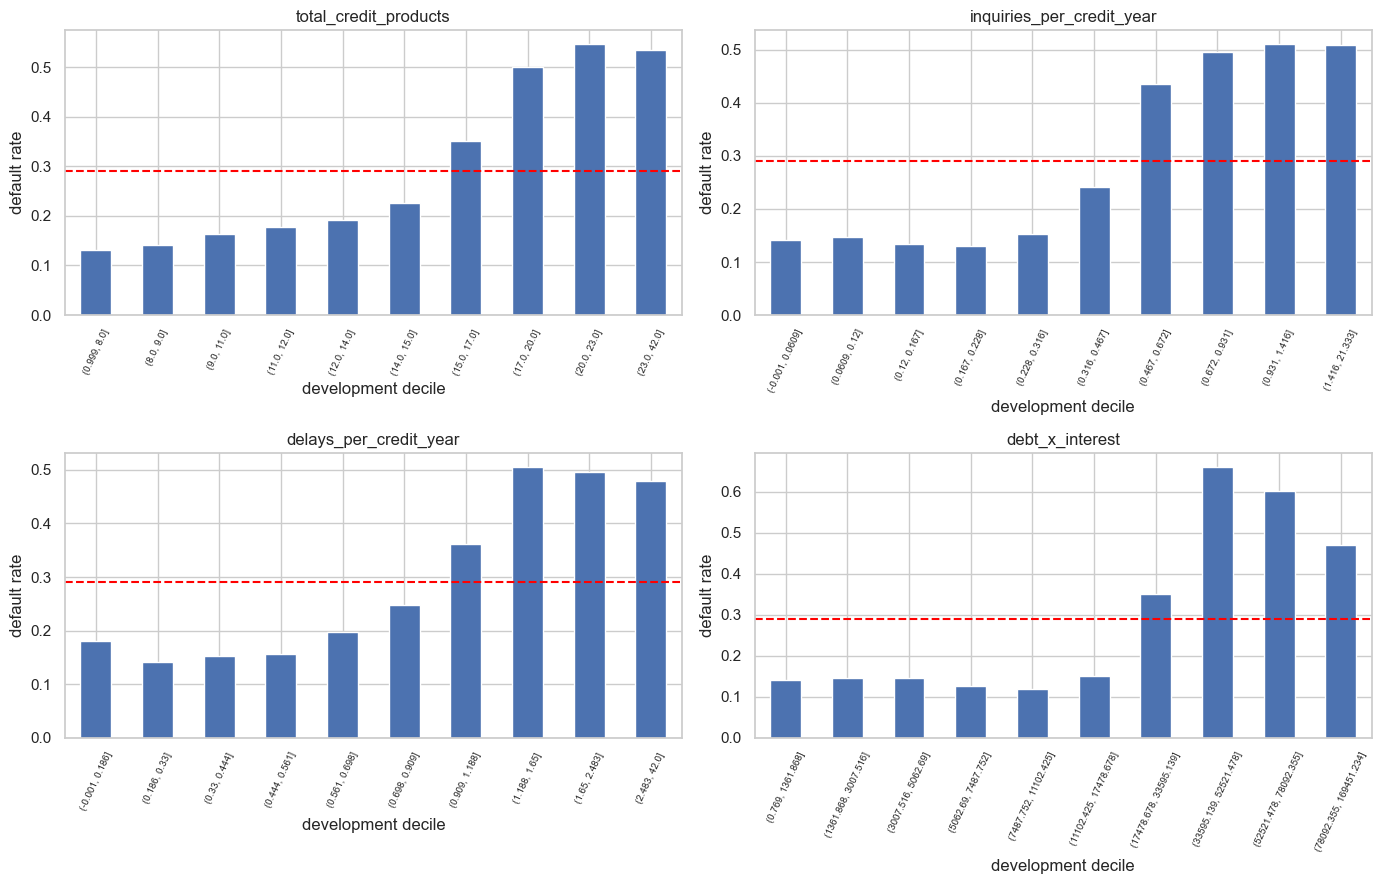

In [5]:
period_profiles = pd.concat(
    {
        period: numeric_profile(part, ARITHMETIC)[['n', 'auc', 'ranking_auc']]
        for period, part in development.groupby('eda_period')
    },
    names=['period', 'feature'],
)
display(period_profiles.round(4))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, column in zip(axes.flat, ARITHMETIC):
    valid = development[[column, 'label']].dropna().copy()
    valid['decile'] = pd.qcut(valid[column], 10, duplicates='drop')
    curve = valid.groupby('decile', observed=True)['label'].agg(n='size', default_rate='mean')
    curve['default_rate'].plot.bar(ax=ax)
    ax.axhline(development.label.mean(), color='red', linestyle='--', label='overall')
    ax.set_title(column)
    ax.set_xlabel('development decile')
    ax.set_ylabel('default rate')
    ax.tick_params(axis='x', rotation=65, labelsize=7)
plt.tight_layout()
plt.show()

## 3. Loan-type multi-hot candidates

`type_of_loan` is loaded from the application-month raw financial record because the current gold table intentionally drops the original text. The indicators represent membership, so one applicant may have several indicators equal to one.

This assumes existing loan types are available from the credit report at application time. That assumption should be confirmed before production use.

In [6]:
raw_financials = pd.read_csv(DATA / 'features_financials.csv', dtype=str)
raw_financials.columns = raw_financials.columns.str.lower()
raw_financials['snapshot_date'] = pd.to_datetime(raw_financials['snapshot_date'])
assert not raw_financials.duplicated(['customer_id', 'snapshot_date']).any()

development = development.merge(
    raw_financials[['customer_id', 'snapshot_date', 'type_of_loan']],
    left_on=['customer_id', 'application_date'],
    right_on=['customer_id', 'snapshot_date'],
    how='left',
    validate='one_to_one',
    suffixes=('', '_raw'),
)

LOAN_TYPES = [
    'Auto Loan',
    'Credit-Builder Loan',
    'Personal Loan',
    'Home Equity Loan',
    'Mortgage Loan',
    'Student Loan',
    'Debt Consolidation Loan',
    'Payday Loan',
    'Not Specified',
]

def indicator_name(value):
    return 'has_' + value.lower().replace('-', '_').replace(' ', '_')

loan_text = development['type_of_loan'].fillna('')
LOAN_INDICATORS = []
for loan_type in LOAN_TYPES:
    column = indicator_name(loan_type)
    development[column] = loan_text.str.contains(re.escape(loan_type), regex=True).astype('int8')
    LOAN_INDICATORS.append(column)

development['loan_type_missing'] = loan_text.eq('').astype('int8')
LOAN_INDICATORS.append('loan_type_missing')

# Count list entries only as a source-quality check; "and" is presentation text.
parsed_count = loan_text.apply(
    lambda value: 0 if not value else len(re.split(r',\s*|,?\s+and\s+', value))
)
count_comparison = development['num_of_loan'].notna() & ~development['loan_type_missing'].astype(bool)
print(f'Missing loan-type list: {development.loan_type_missing.mean():.2%}')
print('Parsed count agrees with cleaned num_of_loan on comparable rows:',
      f'{(parsed_count[count_comparison] == development.loc[count_comparison, "num_of_loan"]).mean():.2%}')
unparsed_text = loan_text.copy()
for loan_type in sorted(LOAN_TYPES, key=len, reverse=True):
    unparsed_text = unparsed_text.str.replace(re.escape(loan_type), '', regex=True)
unparsed_text = unparsed_text.str.replace(r'\band\b|,|\s+', '', regex=True)
print('Rows containing unexpected loan-type text:', int(unparsed_text.ne('').sum()))

Missing loan-type list: 11.44%
Parsed count agrees with cleaned num_of_loan on comparable rows: 99.97%
Rows containing unexpected loan-type text: 0


,n_yes,default_if_no,default_if_yes,ranking_auc
loan_type,,,,
Credit-Builder Loan,3492,0.2546,0.3666,0.5590
Student Loan,3387,0.2551,0.3688,0.5589
Auto Loan,3360,0.2561,0.3676,0.5575
Home Equity Loan,3439,0.2566,0.3638,0.5560
Not Specified,3470,0.2566,0.3628,0.5557
Personal Loan,3415,0.2569,0.3640,0.5557
Mortgage Loan,3458,0.2576,0.3612,0.5543
Debt Consolidation Loan,3395,0.2587,0.3605,0.5528
Payday Loan,3495,0.2583,0.3585,0.5528


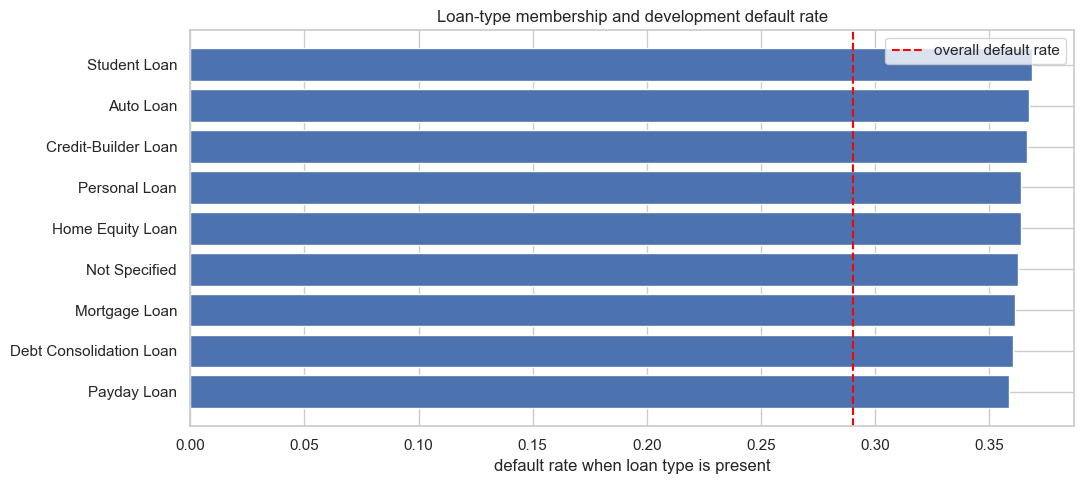

In [7]:
loan_rows = []
for loan_type, column in zip(LOAN_TYPES + ['Missing list'], LOAN_INDICATORS):
    rates = development.groupby(column)['label'].agg(n='size', default_rate='mean')
    auc = roc_auc_score(development.label, development[column])
    loan_rows.append({
        'loan_type': loan_type,
        'n_yes': int(development[column].sum()),
        'default_if_no': rates.loc[0, 'default_rate'],
        'default_if_yes': rates.loc[1, 'default_rate'],
        'ranking_auc': max(auc, 1 - auc),
    })
loan_summary = pd.DataFrame(loan_rows).set_index('loan_type').sort_values('ranking_auc', ascending=False)
display(loan_summary.round(4))

fig, ax = plt.subplots(figsize=(11, 5))
plot_data = loan_summary.drop(index='Missing list').sort_values('default_if_yes')
ax.barh(plot_data.index, plot_data.default_if_yes)
ax.axvline(development.label.mean(), color='red', linestyle='--', label='overall default rate')
ax.set_xlabel('default rate when loan type is present')
ax.set_title('Loan-type membership and development default rate')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Occupation EDA

Occupation is already retained in gold. The model comparison below determines whether one-hot encoding it adds value after controlling for all other current features. Category-level rates alone can be misleading because they do not control for the applicant's financial characteristics.

,n,defaults,default_rate
occupation,,,
Mechanic,683,213,0.3119
Writer,637,198,0.3108
Accountant,703,215,0.3058
Engineer,690,211,0.3058
Teacher,688,208,0.3023
Manager,640,190,0.2969
MISSING,774,227,0.2933
Developer,684,200,0.2924
Doctor,674,195,0.2893


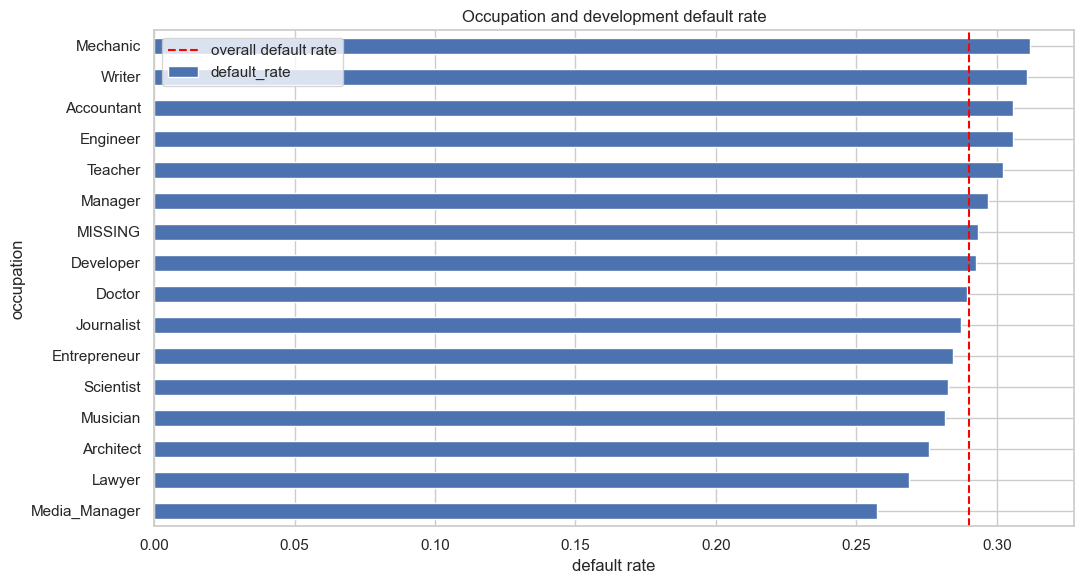

Observed occupation default-rate spread: 5.47%


In [8]:
occupation_summary = (
    development.assign(occupation=development.occupation.fillna('MISSING'))
    .groupby('occupation')['label']
    .agg(n='size', defaults='sum', default_rate='mean')
    .sort_values('default_rate', ascending=False)
)
display(occupation_summary.round(4))

fig, ax = plt.subplots(figsize=(11, 6))
occupation_summary.sort_values('default_rate')['default_rate'].plot.barh(ax=ax)
ax.axvline(development.label.mean(), color='red', linestyle='--', label='overall default rate')
ax.set_title('Occupation and development default rate')
ax.set_xlabel('default rate')
ax.legend()
plt.tight_layout()
plt.show()

spread = occupation_summary.default_rate.max() - occupation_summary.default_rate.min()
print(f'Observed occupation default-rate spread: {spread:.2%}')

## 5. Small clickstream recency and volatility subset

Based on the initial EDA, the latest values are limited to `fe_3`, `fe_4`, `fe_5`, `fe_9`, and `fe_10`. Only `fe_15` volatility is tested. This avoids creating latest, trend, and volatility variants for all 20 anonymous features.

Volatility is missing unless at least three historical observations exist. This prevents a one-month history from being represented as genuine zero volatility.

In [9]:
clickstream = pd.read_csv(DATA / 'feature_clickstream.csv')
clickstream.columns = clickstream.columns.str.lower()
clickstream['snapshot_date'] = pd.to_datetime(clickstream['snapshot_date'])
assert not clickstream.duplicated(['customer_id', 'snapshot_date']).any()

application_keys = development[['customer_id', 'application_date']]
click_window = clickstream.merge(application_keys, on='customer_id', how='inner', validate='many_to_one')
click_window = click_window.loc[
    (click_window.snapshot_date <= click_window.application_date)
    & (click_window.snapshot_date >= click_window.application_date - pd.DateOffset(months=11))
].sort_values(['customer_id', 'snapshot_date'])

# Explicit point-in-time assertion: no post-application event enters an aggregate.
assert (click_window.snapshot_date <= click_window.application_date).all()

by_customer = click_window.groupby('customer_id', sort=False)
click_features = pd.DataFrame(index=by_customer.size().index)
click_features['clickstream_months_observed'] = by_customer.size()

LATEST_SOURCE = ['fe_3', 'fe_4', 'fe_5', 'fe_9', 'fe_10']
CLICK_CANDIDATES = []
for source in LATEST_SOURCE:
    column = f'{source}_latest'
    click_features[column] = by_customer[source].last()
    CLICK_CANDIDATES.append(column)

click_features['fe_15_std_12m'] = by_customer['fe_15'].std(ddof=0)
click_features.loc[click_features.clickstream_months_observed < 3, 'fe_15_std_12m'] = np.nan
CLICK_CANDIDATES.append('fe_15_std_12m')

development = development.merge(
    click_features,
    left_on='customer_id',
    right_index=True,
    how='left',
    validate='one_to_one',
)

print('Point-in-time clickstream rows:', len(click_window))
print('Customers with any history:', development.clickstream_months_observed.notna().sum())
print('Observed-month distribution:')
display(development.clickstream_months_observed.value_counts(dropna=False).sort_index())
display(numeric_profile(development, CLICK_CANDIDATES).round(4))

Point-in-time clickstream rows: 74359
Customers with any history: 8974
Observed-month distribution:


clickstream_months_observed
1.0      530
2.0      501
3.0      506
4.0      510
5.0      521
6.0      517
7.0      471
8.0      481
9.0      454
10.0     487
11.0     491
12.0    3505
NaN     1997
Name: count, dtype: int64

,n,missing_pct,auc,ranking_auc,median_nondefault,median_default
feature,,,,,,
fe_10_latest,8974,18.2025,0.4229,0.5771,126.0000,100.0000
fe_5_latest,8974,18.2025,0.5676,0.5676,101.0000,126.0000
fe_15_std_12m,7943,27.6000,0.5591,0.5591,88.8079,94.7548
fe_4_latest,8974,18.2025,0.5528,0.5528,100.0000,119.0000
fe_9_latest,8974,18.2025,0.4476,0.5524,117.0000,99.0000
fe_3_latest,8974,18.2025,0.5500,0.5500,98.0000,115.0000


n     auc  ranking_auc
period              feature                                 
earlier development fe_10_latest   5958  0.4176       0.5824
                    fe_5_latest    5958  0.5776       0.5776
                    fe_4_latest    5958  0.5568       0.5568
                    fe_9_latest    5958  0.4432       0.5568
                    fe_15_std_12m  4927  0.5507       0.5507
                    fe_3_latest    5958  0.5503       0.5503
later development   fe_15_std_12m  3016  0.5722       0.5722
                    fe_10_latest   3016  0.4337       0.5663
                    fe_3_latest    3016  0.5497       0.5497
                    fe_5_latest    3016  0.5481       0.5481
                    fe_4_latest    3016  0.5453       0.5453
                    fe_9_latest    3016  0.4558       0.5442

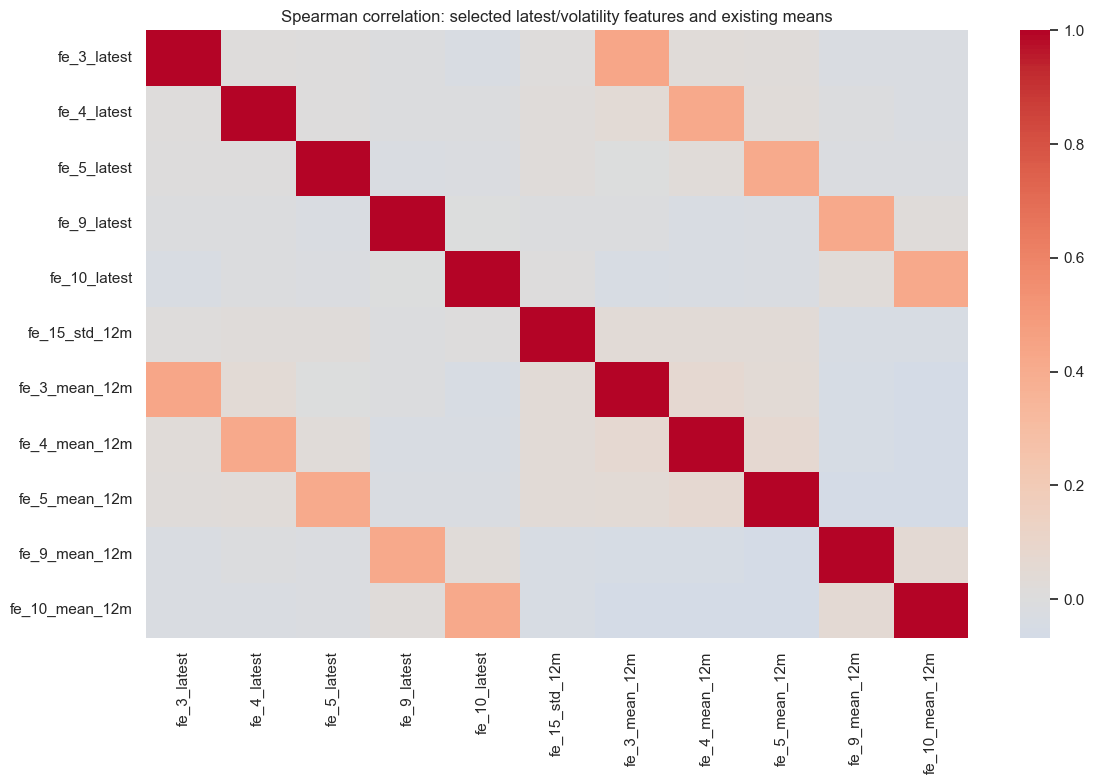

In [10]:
click_period_profiles = pd.concat(
    {
        period: numeric_profile(part, CLICK_CANDIDATES)[['n', 'auc', 'ranking_auc']]
        for period, part in development.groupby('eda_period')
    },
    names=['period', 'feature'],
)
display(click_period_profiles.round(4))

comparison_columns = CLICK_CANDIDATES + [f'{source}_mean_12m' for source in LATEST_SOURCE]
plt.figure(figsize=(12, 8))
sns.heatmap(development[comparison_columns].corr(method='spearman'), cmap='coolwarm', center=0, annot=False)
plt.title('Spearman correlation: selected latest/volatility features and existing means')
plt.tight_layout()
plt.show()

## 6. Does one-hot encoding loan type or occupation add validation value?

The comparison below uses a chronological split:

- **Train:** label dates before July 2024
- **Validation:** label dates from July 2024 through April 2025
- **Reserved:** May 2025 onward, not scored here

The baseline contains all current gold features except occupation. Therefore:

- `+ occupation` isolates the value of one-hot encoded occupation.
- `+ loan types` isolates multi-hot loan-type value while `num_of_loan` remains in the baseline.
- The final rows test the requested numerical and clickstream candidates.

Two model forms are used because engineered interactions may help a linear model differently from a nonlinear model. A small AUC difference on one split is not proof of durable improvement.

In [11]:
CURRENT_COLUMNS = [
    column for column in features.columns
    if column not in {'customer_id', 'snapshot_date'}
]
BASE_WITHOUT_OCCUPATION = [column for column in CURRENT_COLUMNS if column != 'occupation']

FEATURE_SETS = {
    'baseline without occupation': BASE_WITHOUT_OCCUPATION,
    '+ occupation one-hot': BASE_WITHOUT_OCCUPATION + ['occupation'],
    '+ loan-type multi-hot': BASE_WITHOUT_OCCUPATION + LOAN_INDICATORS,
    '+ arithmetic candidates': BASE_WITHOUT_OCCUPATION + ARITHMETIC,
    '+ clickstream candidates': BASE_WITHOUT_OCCUPATION + CLICK_CANDIDATES,
    '+ occupation and loan types': BASE_WITHOUT_OCCUPATION + ['occupation'] + LOAN_INDICATORS,
    '+ occupation, loan types, arithmetic': (
        BASE_WITHOUT_OCCUPATION + ['occupation'] + LOAN_INDICATORS + ARITHMETIC
    ),
    '+ occupation, loan types, clickstream': (
        BASE_WITHOUT_OCCUPATION + ['occupation'] + LOAN_INDICATORS + CLICK_CANDIDATES
    ),
    '+ all requested candidates': (
        BASE_WITHOUT_OCCUPATION + ['occupation'] + LOAN_INDICATORS
        + ARITHMETIC + CLICK_CANDIDATES
    ),
}

train_mask = development.label_date < VALIDATION_LABEL_START
validation_mask = ~train_mask
print('Training rows:', train_mask.sum(), 'validation rows:', validation_mask.sum())
print('Training default rate:', f'{development.loc[train_mask, "label"].mean():.2%}')
print('Validation default rate:', f'{development.loc[validation_mask, "label"].mean():.2%}')


def build_model(frame, columns, model_kind):
    categorical = [column for column in columns if frame[column].dtype == 'object']
    numeric = [column for column in columns if column not in categorical]

    if model_kind == 'logistic':
        numeric_pipe = make_pipeline(
            SimpleImputer(strategy='median', add_indicator=True),
            StandardScaler(),
        )
        estimator = LogisticRegression(C=0.3, max_iter=2000)
    elif model_kind == 'hist_gradient_boosting':
        numeric_pipe = SimpleImputer(strategy='median', add_indicator=True)
        estimator = HistGradientBoostingClassifier(
            max_iter=150,
            max_leaf_nodes=15,
            learning_rate=0.06,
            l2_regularization=2,
            random_state=42,
        )
    else:
        raise ValueError(model_kind)

    categorical_pipe = make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore', sparse_output=False),
    )
    processor = ColumnTransformer([
        ('numeric', numeric_pipe, numeric),
        ('categorical', categorical_pipe, categorical),
    ])
    return make_pipeline(processor, estimator)

predictions = {}
rows = []
for model_kind in ['logistic', 'hist_gradient_boosting']:
    for feature_set, columns in FEATURE_SETS.items():
        model = build_model(development, columns, model_kind)
        model.fit(development.loc[train_mask, columns], development.loc[train_mask, 'label'])
        prediction = model.predict_proba(development.loc[validation_mask, columns])[:, 1]
        predictions[(model_kind, feature_set)] = prediction
        rows.append({
            'model': model_kind,
            'feature_set': feature_set,
            'n_features_before_encoding': len(columns),
            'validation_auc': roc_auc_score(development.loc[validation_mask, 'label'], prediction),
        })

model_results = pd.DataFrame(rows)
baseline_auc = model_results.loc[
    model_results.feature_set == 'baseline without occupation',
    ['model', 'validation_auc'],
].rename(columns={'validation_auc': 'baseline_auc'})
model_results = model_results.merge(baseline_auc, on='model')
model_results['delta_vs_baseline'] = model_results.validation_auc - model_results.baseline_auc
display(model_results.drop(columns='baseline_auc').set_index(['model', 'feature_set']).round(4))

Training rows: 5958 validation rows: 5013
Training default rate: 28.30%
Validation default rate: 29.88%


n_features_before_encoding  validation_auc  delta_vs_baseline
model                  feature_set                                                                                         
logistic               baseline without occupation                                    43          0.8475             0.0000
                       + occupation one-hot                                           44          0.8455            -0.0019
                       + loan-type multi-hot                                          53          0.8451            -0.0024
                       + arithmetic candidates                                        47          0.8482             0.0007
                       + clickstream candidates                                       49          0.8458            -0.0017
                       + occupation and loan types                                    54          0.8436            -0.0039
                       + occupation, loan types, arithmetic                           58          0.8444            -0.0031
                       + occupation, loan types, clickstream                          60          0.8418            -0.0056
                       + all requested candidates                                     64          0.8429            -0.0046
hist_gradient_boosting baseline without occupation                                    43          0.8633             0.0000
                       + occupation one-hot                                           44          0.8635             0.0002
                       + loan-type multi-hot                                          53          0.8658             0.0025
                       + arithmetic candidates                                        47          0.8672             0.0039
                       + clickstream candidates                                       49          0.8658             0.0025
                       + occupation and loan types                                    54          0.8688             0.0056
                       + occupation, loan types, arithmetic                           58          0.8666             0.0033
                       + occupation, loan types, clickstream                          60          0.8630            -0.0003
                       + all requested candidates                                     64          0.8631            -0.0002

### Paired bootstrap uncertainty for occupation and loan types

Validation rows are resampled as pairs so each feature set is compared on exactly the same applications. The interval captures sampling uncertainty within this validation period, but not future drift, feature-definition uncertainty, or repeated feature-selection bias.

In [12]:
validation_y = development.loc[validation_mask, 'label'].to_numpy()
rng = np.random.default_rng(611)
bootstrap_rows = []
N_BOOTSTRAP = 500

for model_kind in ['logistic', 'hist_gradient_boosting']:
    baseline = predictions[(model_kind, 'baseline without occupation')]
    for feature_set in ['+ occupation one-hot', '+ loan-type multi-hot', '+ occupation and loan types']:
        candidate = predictions[(model_kind, feature_set)]
        differences = []
        for _ in range(N_BOOTSTRAP):
            index = rng.integers(0, len(validation_y), len(validation_y))
            if np.unique(validation_y[index]).size < 2:
                continue
            differences.append(
                roc_auc_score(validation_y[index], candidate[index])
                - roc_auc_score(validation_y[index], baseline[index])
            )
        point = (
            roc_auc_score(validation_y, candidate)
            - roc_auc_score(validation_y, baseline)
        )
        low, high = np.quantile(differences, [0.025, 0.975])
        bootstrap_rows.append({
            'model': model_kind,
            'feature_set': feature_set,
            'auc_delta': point,
            'bootstrap_2.5%': low,
            'bootstrap_97.5%': high,
        })

bootstrap_results = pd.DataFrame(bootstrap_rows).set_index(['model', 'feature_set'])
display(bootstrap_results.round(4))

auc_delta  bootstrap_2.5%  bootstrap_97.5%
model                  feature_set                                                            
logistic               + occupation one-hot           -0.0019         -0.0036          -0.0003
                       + loan-type multi-hot          -0.0024         -0.0039          -0.0010
                       + occupation and loan types    -0.0039         -0.0058          -0.0018
hist_gradient_boosting + occupation one-hot            0.0002         -0.0013           0.0015
                       + loan-type multi-hot           0.0025          0.0007           0.0045
                       + occupation and loan types     0.0056          0.0035           0.0076

## 7. Decision guide

Use the executed tables above rather than category-rate differences alone.

- **Occupation:** retain it only if the chronological AUC delta is consistently positive and meaningful. Otherwise it adds dimensionality, possible fairness/proxy concerns, and maintenance cost without demonstrated value.
- **Loan types:** multi-hot is the correct representation because each applicant can have multiple loan types. Compare it against a baseline that already contains `num_of_loan`; otherwise the apparent gain may only reflect loan count.
- **Arithmetic candidates:** prioritize stable features that add model value beyond their raw components. Keep raw components in gold for flexibility.
- **Clickstream:** prefer the existing 12-month means unless latest/volatility adds repeatable chronological validation value. Do not expand all 20 anonymous features without evidence.
- **Before implementation:** repeat the comparison across more than one rolling-origin split and leave the reserved final cohort untouched for confirmation.

### Findings from this run

- All four arithmetic candidates have stable univariate associations. As a group they changed temporal validation AUC by **+0.0007** for logistic regression and **+0.0039** for the nonlinear model. They are promising, but the gain is model-dependent.
- Occupation one-hot changed AUC by **-0.0019** for logistic regression and **+0.0002** for the nonlinear model. Its nonlinear paired-bootstrap interval crosses zero, so this run shows **no reliable standalone value from occupation**.
- Loan-type multi-hot changed AUC by **-0.0024** for logistic regression and **+0.0025** for the nonlinear model. The nonlinear paired-bootstrap interval is **[+0.0007, +0.0045]**, so loan type is a reasonable candidate for further time-split validation, but not yet a model-independent win.
- The selected clickstream latest/volatility group changed AUC by **-0.0017** for logistic regression and **+0.0025** for the nonlinear model. Existing 12-month means remain the safer default because the latest values are weaker univariately and history is left-censored for early applicants.
- Adding every candidate at once did not improve either model. This supports a compact feature set rather than retaining all engineered columns.

**EDA recommendation:** take the arithmetic group and loan-type indicators to rolling-origin validation. Do not add occupation solely for predictive performance, and defer the clickstream recency/volatility subset unless its gain repeats across time splits.

No persisted data or pipeline code is changed by this notebook.